# FINC 3390 - Homework 5

**Student:** Dekena Wade  
**Semester:** Fall 2026  
**Submission format:** Individual

## Goal

Replicate the seven assigned plots comparing S&P 500 realized volatility, the VIX, crisis-period index behavior, and daily market returns.

## Current date, time, and weekday

In [1]:
from datetime import datetime
from zoneinfo import ZoneInfo

new_york_now = datetime.now(ZoneInfo("America/New_York"))
print(new_york_now.strftime("Now %Y-%m-%d %I:%M:%S %p %Z, %A"))

Now 2026-10-27 04:43:11 PM EDT, Tuesday


## Data and method

S&P 500 (`^GSPC`) and VIX (`^VIX`) data were downloaded programmatically from Yahoo Finance and embedded for reproducibility.

The daily continuously compounded return is:

\[
r_t = \ln\left(\frac{P_t}{P_{t-1}}\right).
\]

Rolling realized volatility is the sample standard deviation of daily log returns, annualized using 252 trading days:

\[
\sigma_{annual,t} = SD(r_{t-n+1},\ldots,r_t)\sqrt{252}\times 100.
\]

VIX is different: it is a market-implied, forward-looking estimate of approximately 30-day S&P 500 volatility, quoted at an annualized percentage rate.

In [2]:
import base64
import gzip
from io import BytesIO

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.figsize": (12, 7),
    "axes.titlesize": 18,
    "axes.labelsize": 14,
    "legend.fontsize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

EMBEDDED_HW5_DATA = "..."

def load_embedded_market_data(encoded_data):
    raw = gzip.decompress(base64.b64decode(encoded_data))
    frame = pd.read_csv(BytesIO(raw), parse_dates=["Date"])
    frame["Price"] = pd.to_numeric(frame["Price"], errors="coerce")
    return frame.dropna(subset=["Price"]).sort_values(["Ticker", "Date"]).reset_index(drop=True)

market_data = load_embedded_market_data(EMBEDDED_HW5_DATA)
prices = market_data.pivot(index="Date", columns="Ticker", values="Price").sort_index().ffill().dropna()
prices["SP500_daily_return"] = np.log(prices["^GSPC"] / prices["^GSPC"].shift(1))

print(f"Loaded {len(prices):,} aligned trading-day observations from {prices.index.min():%Y-%m-%d} through {prices.index.max():%Y-%m-%d}.")

Loaded 8,754 aligned trading-day observations from 1990-01-02 through 2024-10-01.


In [3]:
def realized_volatility(return_series, window):
    return return_series.rolling(window=window, min_periods=window).std(ddof=1) * np.sqrt(252) * 100

def plot_realized_volatility(window, start="1991-05-01", end="2024-10-01"):
    frame = prices.loc[start:end, ["^VIX"]].copy()
    frame["Realized volatility"] = realized_volatility(prices["SP500_daily_return"], window).loc[start:end]
    frame = frame.dropna()

    fig, axis = plt.subplots(figsize=(12, 7))
    axis.plot(frame.index, frame["Realized volatility"], linewidth=1.4, label="^GSPC")
    axis.plot(frame.index, frame["^VIX"], linewidth=1.4, label="^VIX")
    axis.set_title(f"SP500 volatility vs. VIX from {frame.index.min():%Y-%m-%d} to {frame.index.max():%Y-%m-%d}")
    axis.set_xlabel("date")
    axis.set_ylabel("annualized volatility (%)")
    axis.xaxis.set_major_locator(mdates.YearLocator(4))
    axis.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    axis.legend(loc="upper left")
    axis.grid(True, alpha=0.35)
    fig.tight_layout()
    plt.show()
    return frame

def plot_sp500_vix_window(start, end):
    frame = prices.loc[start:end, ["^GSPC", "^VIX"]].dropna()
    fig, left_axis = plt.subplots(figsize=(12, 7))
    right_axis = left_axis.twinx()
    left_axis.plot(frame.index, frame["^GSPC"], color="red", linewidth=2.5)
    right_axis.plot(frame.index, frame["^VIX"], color="blue", linewidth=1.7)
    left_axis.set_title(f"SP500 vs. VIX from {frame.index.min():%Y-%m-%d} to {frame.index.max():%Y-%m-%d}")
    left_axis.set_xlabel("date")
    left_axis.set_ylabel("SP500", color="red")
    right_axis.set_ylabel("VIX", color="blue")
    left_axis.tick_params(axis="y", colors="red")
    right_axis.tick_params(axis="y", colors="blue")
    left_axis.grid(True, alpha=0.3)
    fig.tight_layout()
    plt.show()
    return frame


## Plots 1-3 - Realized volatility using 21, 126, and 252 trading days

Rolling history: 21 trading days
Rolling history: 126 trading days
Rolling history: 252 trading days


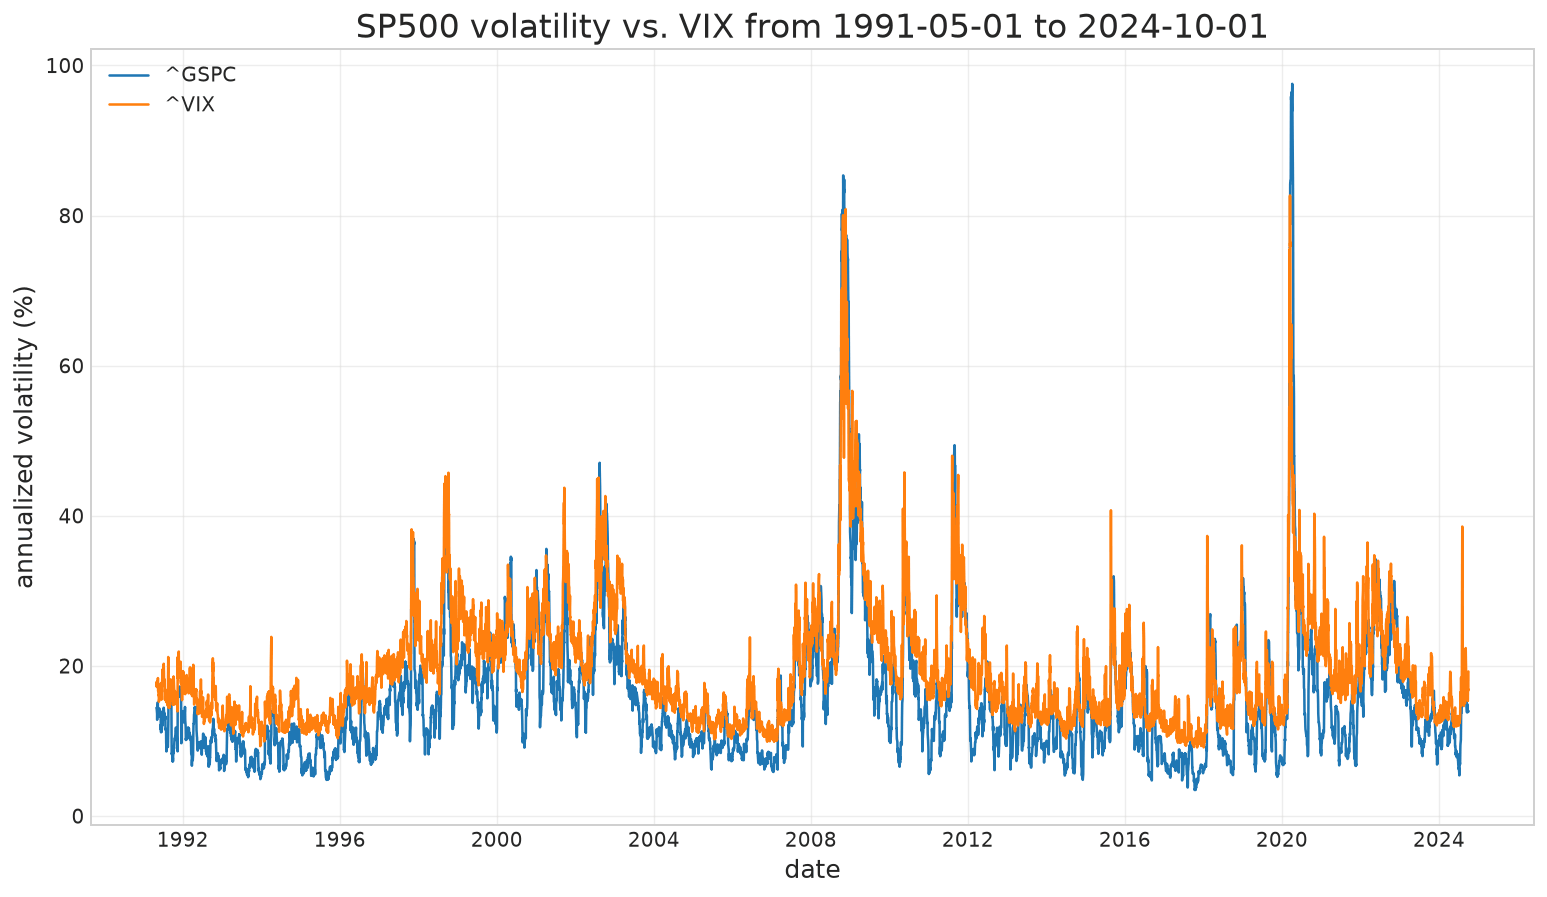

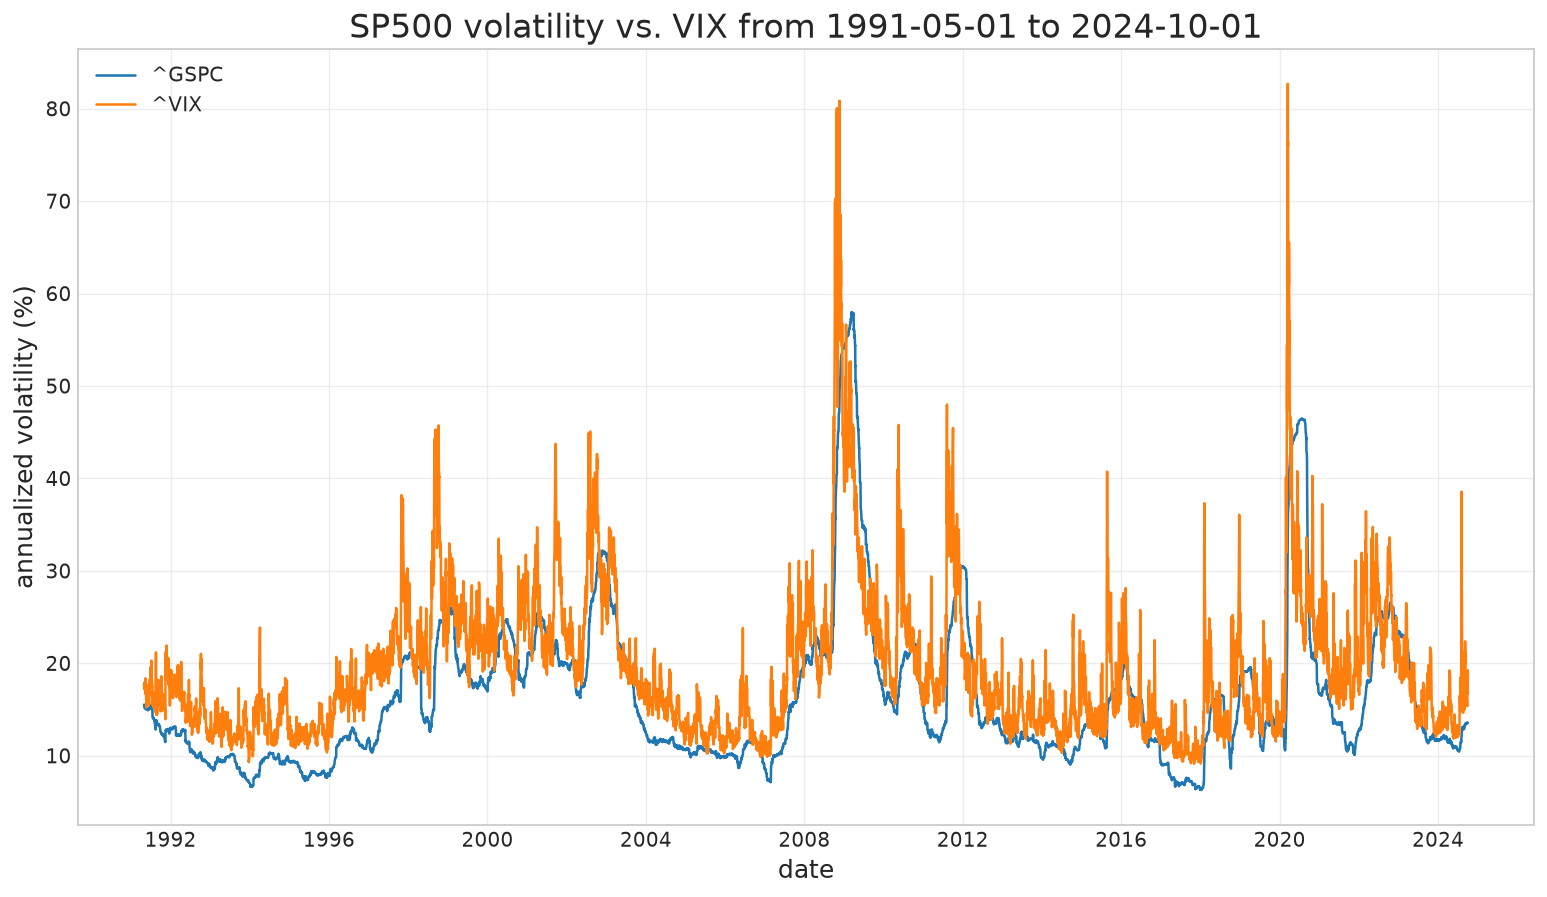

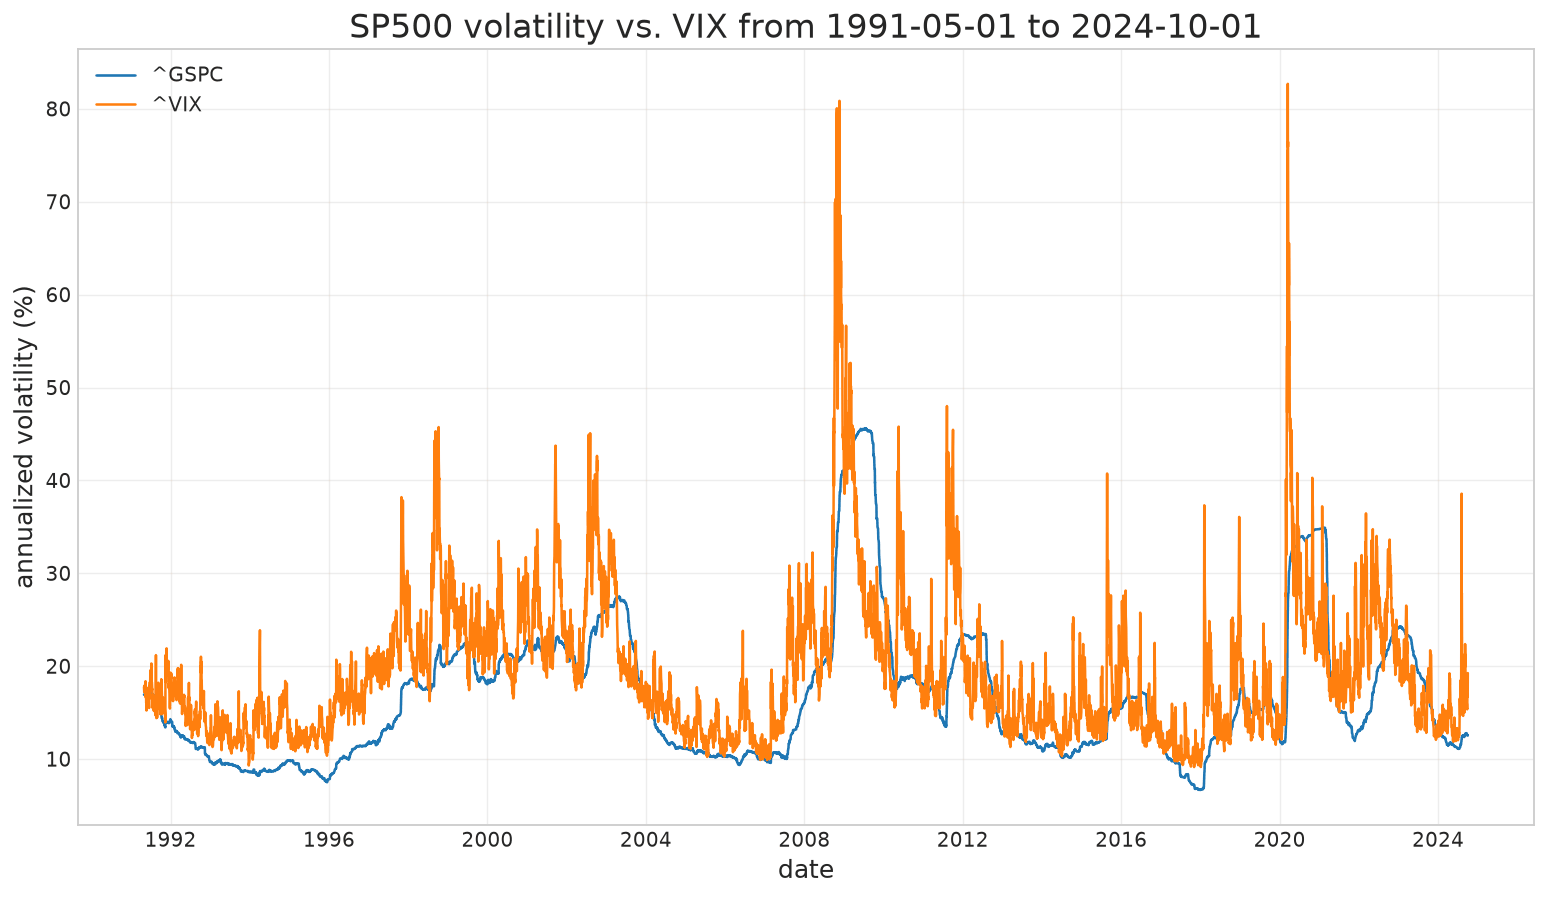

In [4]:
volatility_frames = {}
for window in [21, 126, 252]:
    print(f"Rolling history: {window} trading days")
    volatility_frames[window] = plot_realized_volatility(window)

## Quantifying the realized-volatility versus VIX discrepancy

In [5]:
volatility_comparison = []
for window, frame in volatility_frames.items():
    difference = frame["^VIX"] - frame["Realized volatility"]
    volatility_comparison.append({
        "Rolling history (days)": window,
        "Correlation with VIX": frame["Realized volatility"].corr(frame["^VIX"]),
        "Mean VIX minus realized vol (points)": difference.mean(),
        "Mean absolute gap (points)": difference.abs().mean(),
    })
volatility_comparison = pd.DataFrame(volatility_comparison).set_index("Rolling history (days)")
display(volatility_comparison.style.format("{:.2f}"))

,Correlation with VIX,Mean VIX minus realized vol (points),Mean absolute gap (points)
Rolling history (days),,,
21,0.88,3.91,5.01
126,0.78,3.15,4.65
252,0.69,2.76,4.74


The gap widens as the historical window lengthens because the measures answer increasingly different questions. A 21-day realized measure is close to the VIX's approximate 30-day horizon, while 126- and 252-day windows retain older information and react more slowly to sudden changes. VIX is also forward-looking and includes an option-market volatility risk premium.

## Plots 4-6 - S&P 500 and VIX during major stress periods

2008 Subprime/Lehman crisis
2020 Pandemic crisis
2022 Fed rate hikes


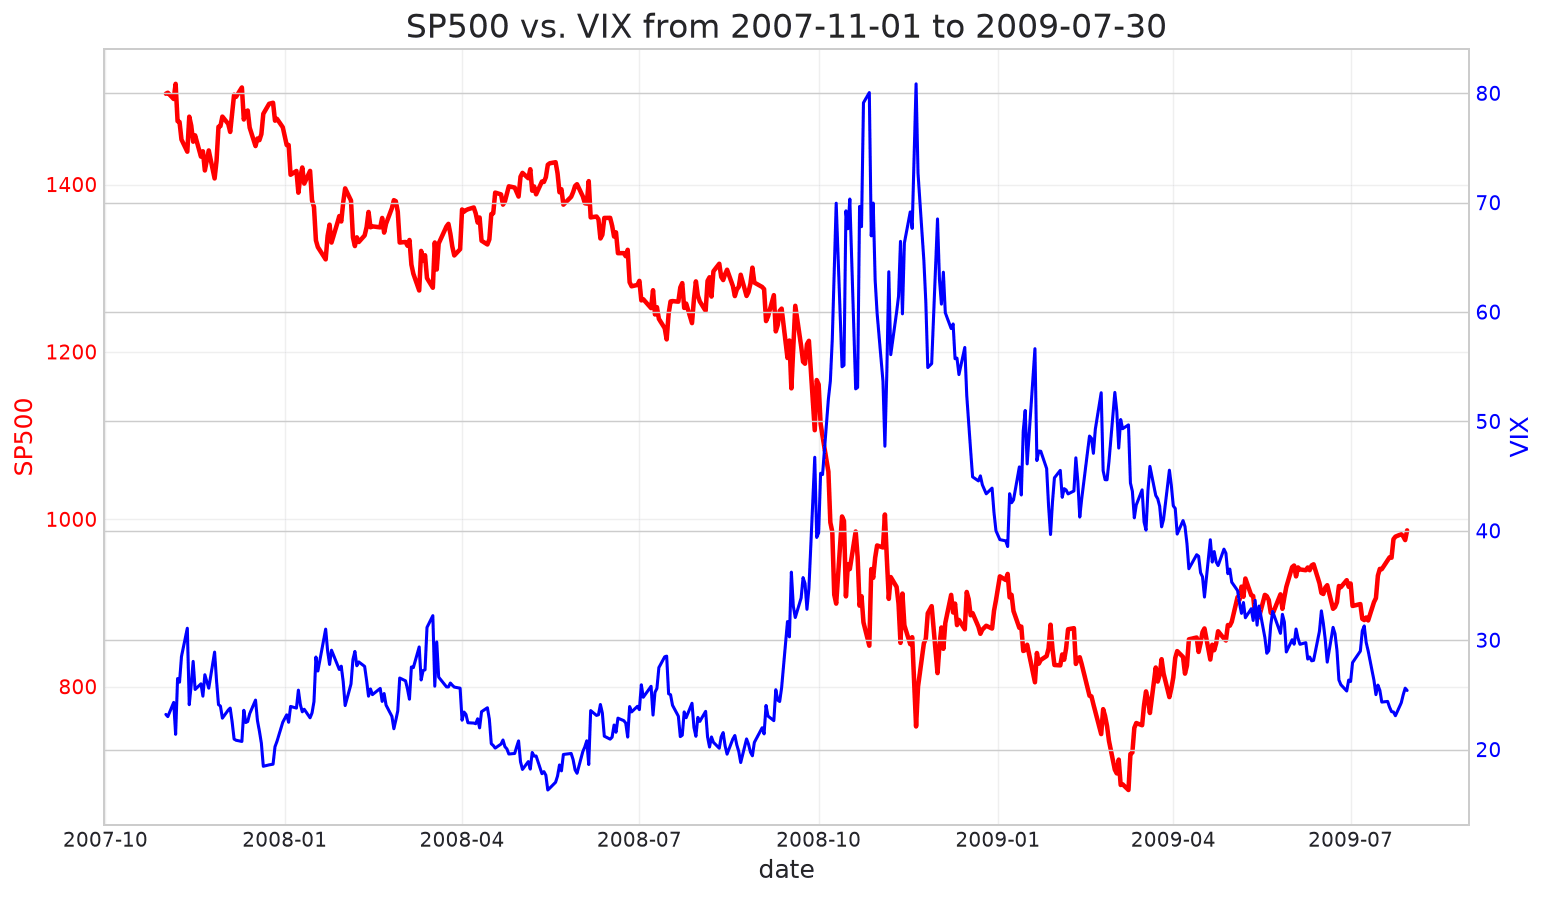

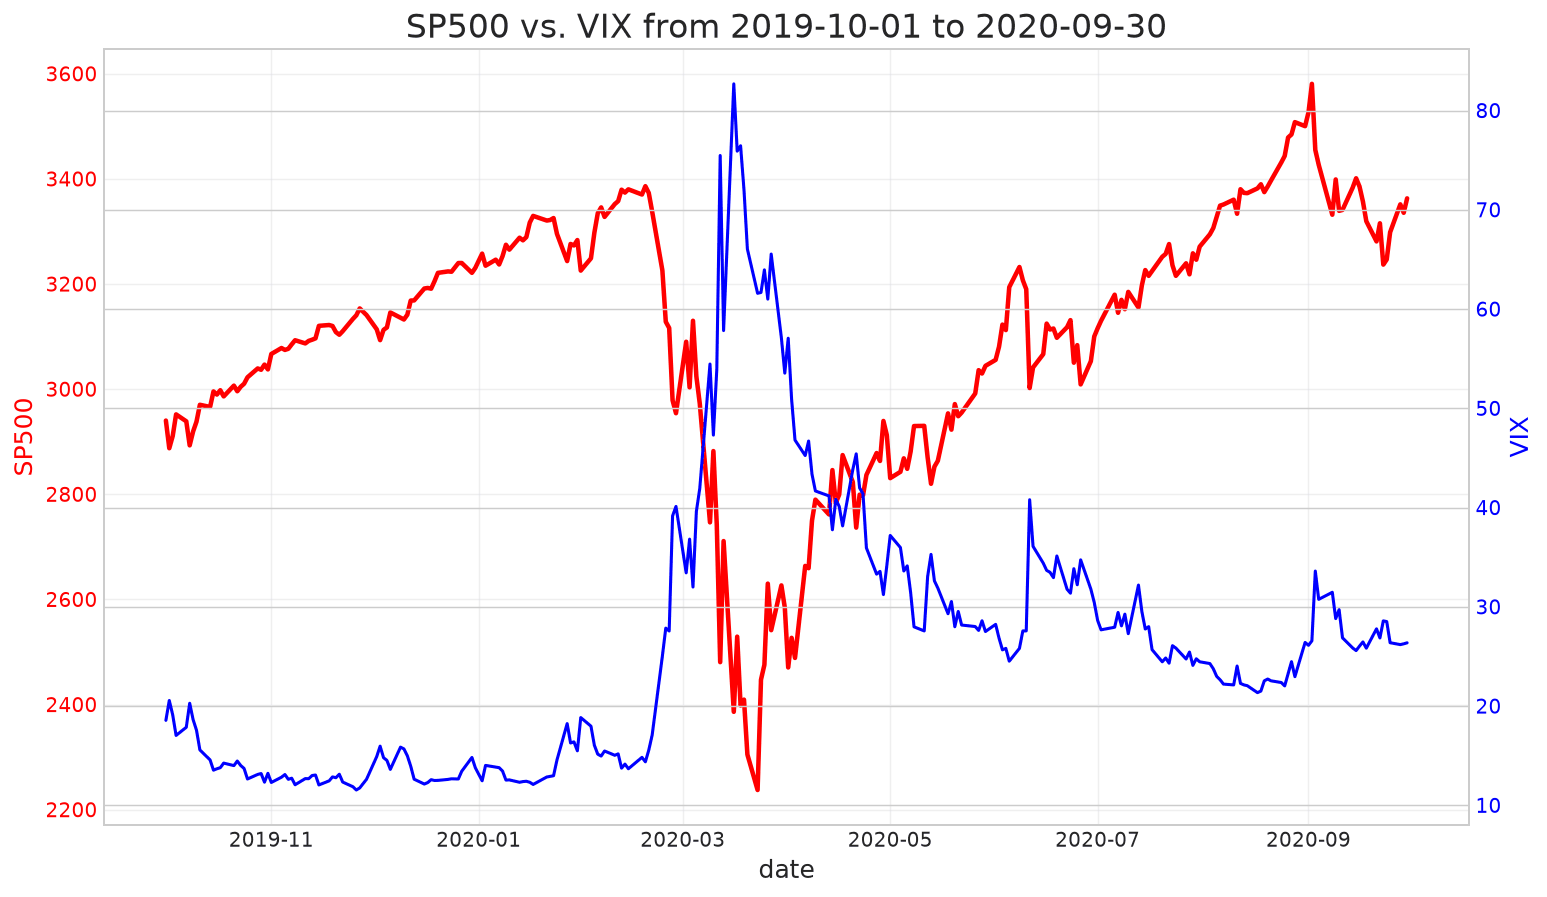

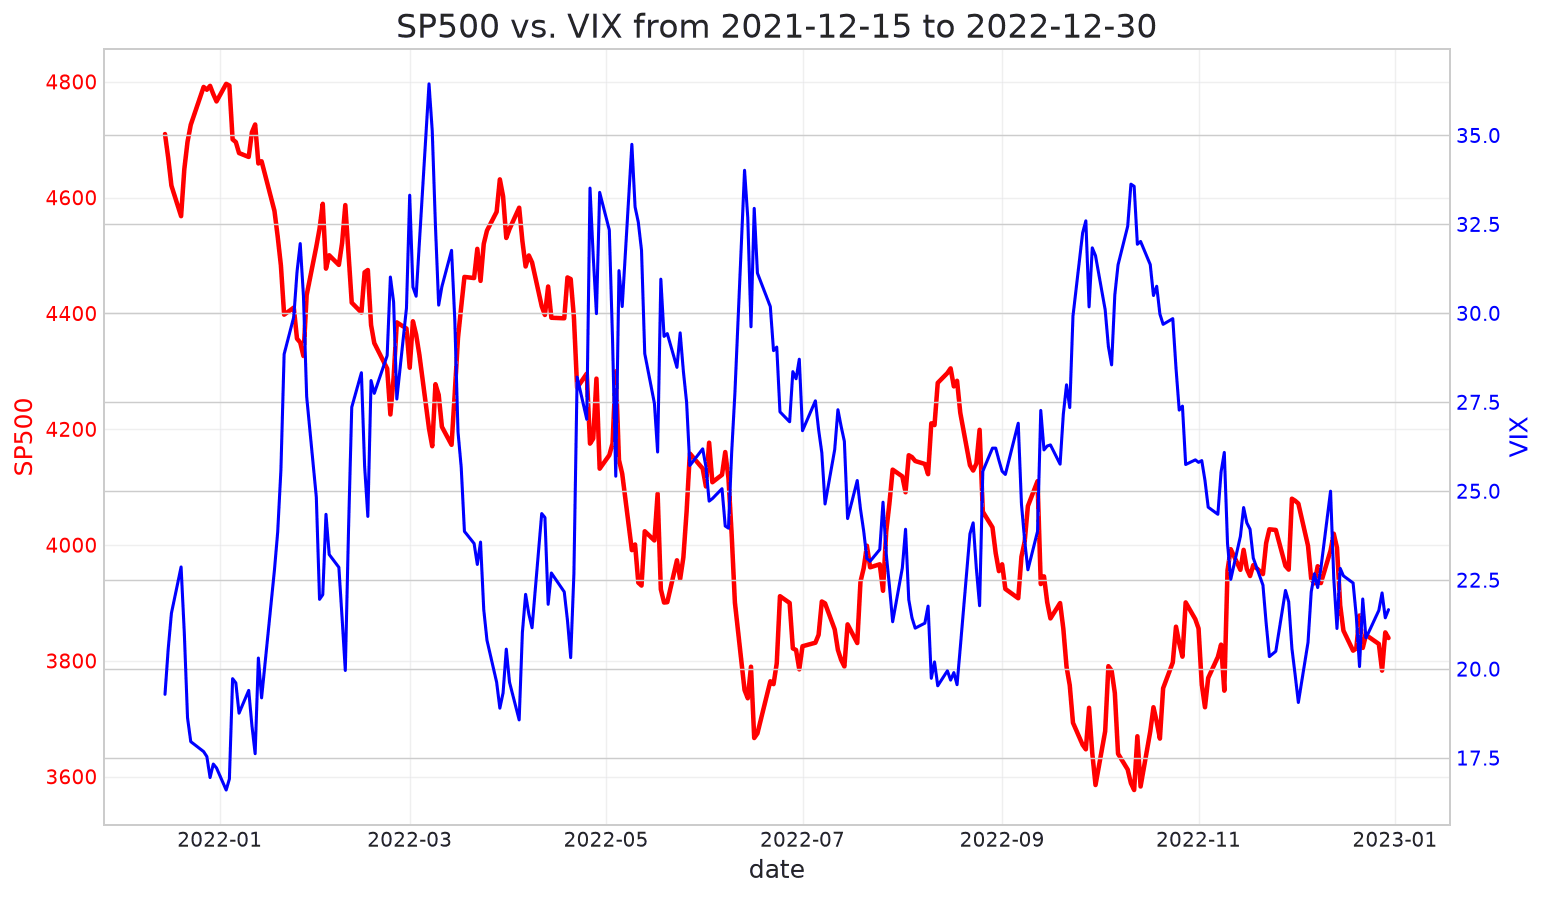

In [6]:
crisis_periods = {
    "2008 Subprime/Lehman crisis": ("2007-11-01", "2009-07-30"),
    "2020 Pandemic crisis": ("2019-10-01", "2020-09-30"),
    "2022 Fed rate hikes": ("2021-12-15", "2022-12-30"),
}

crisis_frames = {}
for crisis_name, (start, end) in crisis_periods.items():
    print(crisis_name)
    crisis_frames[crisis_name] = plot_sp500_vix_window(start, end)

## Crisis-period summary

In [7]:
crisis_summary = []
for crisis_name, frame in crisis_frames.items():
    drawdown = frame["^GSPC"] / frame["^GSPC"].cummax() - 1
    crisis_summary.append({
        "Period": crisis_name,
        "Peak VIX": frame["^VIX"].max(),
        "Peak-VIX date": frame["^VIX"].idxmax().date(),
        "Maximum drawdown": drawdown.min(),
        "Drawdown trough": drawdown.idxmin().date(),
    })
crisis_summary = pd.DataFrame(crisis_summary).set_index("Period")
display(crisis_summary.style.format({"Peak VIX": "{:.2f}", "Maximum drawdown": "{:.1%}"}))

,Peak VIX,Peak-VIX date,Maximum drawdown,Drawdown trough
Period,,,,
2008 Subprime/Lehman crisis,80.86,2008-11-20,-55.5%,2009-03-09
2020 Pandemic crisis,82.69,2020-03-16,-33.9%,2020-03-23
2022 Fed rate hikes,36.45,2022-03-07,-25.4%,2022-10-12


## Plot 7 - S&P 500 daily return and VIX

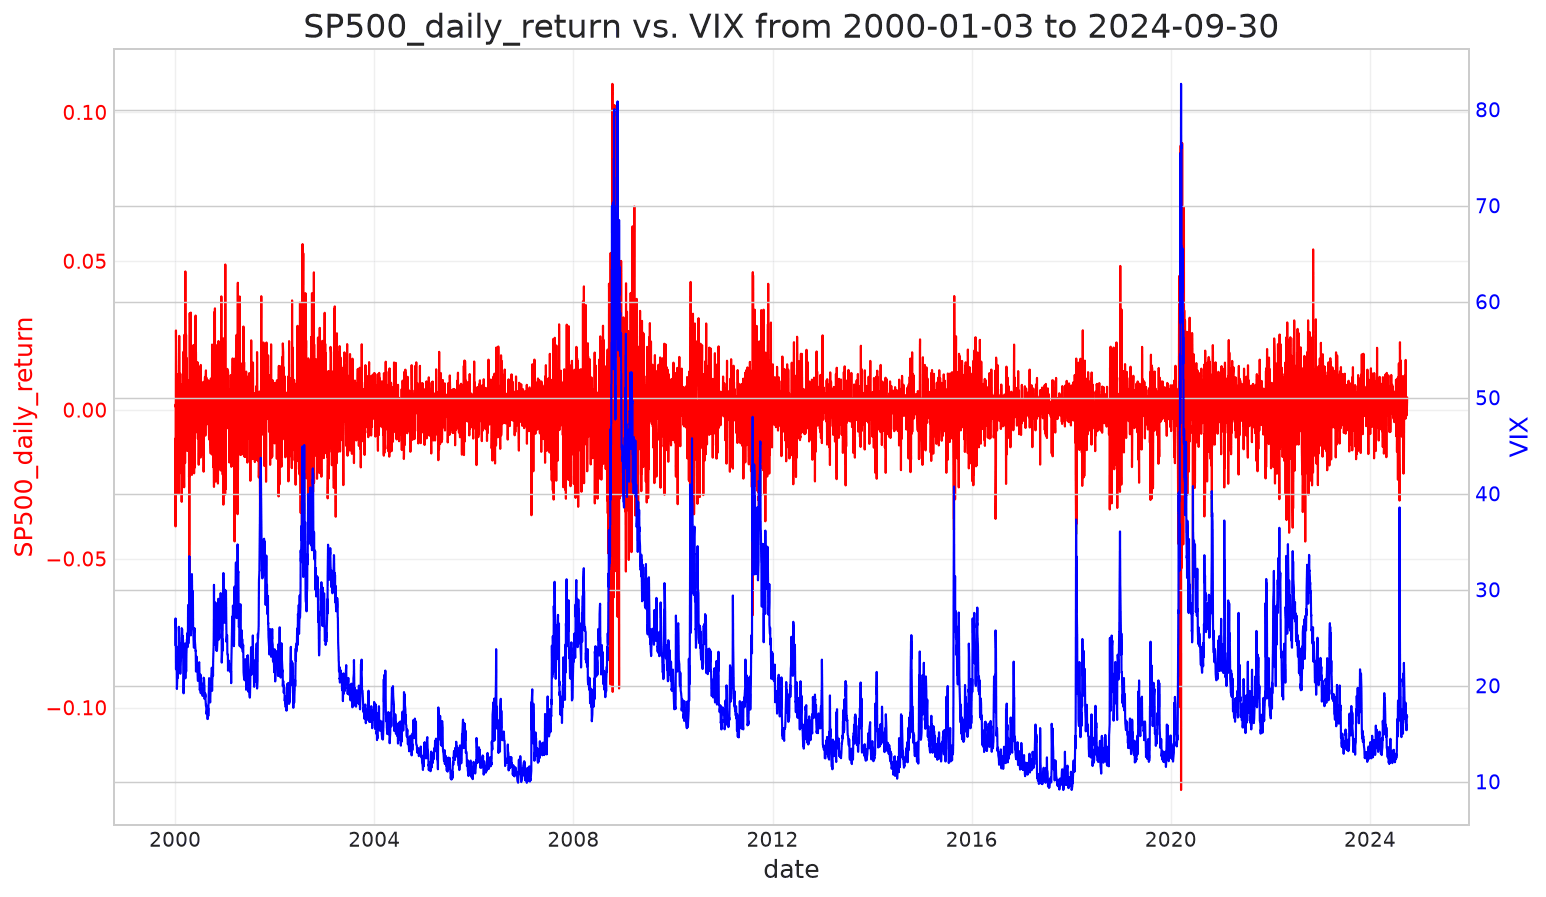

In [8]:
return_vix = prices.loc["2000-01-03":"2024-09-30", ["SP500_daily_return", "^VIX"]].dropna()

fig, left_axis = plt.subplots(figsize=(12, 7))
right_axis = left_axis.twinx()
left_axis.plot(return_vix.index, return_vix["SP500_daily_return"], color="red", linewidth=1.2)
right_axis.plot(return_vix.index, return_vix["^VIX"], color="blue", linewidth=1.2)
left_axis.set_title(f"SP500_daily_return vs. VIX from {return_vix.index.min():%Y-%m-%d} to {return_vix.index.max():%Y-%m-%d}")
left_axis.set_xlabel("date")
left_axis.set_ylabel("SP500_daily_return", color="red")
right_axis.set_ylabel("VIX", color="blue")
left_axis.tick_params(axis="y", colors="red")
right_axis.tick_params(axis="y", colors="blue")
left_axis.xaxis.set_major_locator(mdates.YearLocator(4))
left_axis.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
left_axis.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

## Takeaways

- **Realized versus implied risk:** Rolling volatility summarizes what recently happened; VIX reflects the option market's expectation of near-term volatility.
- **Window choice is a modeling assumption:** Short windows react quickly but are noisy. Long windows are smoother but lag changes.
- **Volatility clustering:** Large returns tend to occur in groups, which is visible around 2008 and 2020.
- **Leverage/fear effect:** Sharp negative S&P 500 returns often coincide with VIX spikes, producing an inverse relationship between market direction and implied volatility.
- **Crisis paths differ:** 2008 was a prolonged financial-system drawdown; 2020 was a sudden shock and rapid policy-supported rebound; 2022 was a persistent repricing under inflation and higher interest rates.

In [9]:
assert prices.index.min() == pd.Timestamp("1990-01-02")
assert prices.index.max() == pd.Timestamp("2024-10-01")
assert set(volatility_frames) == {21, 126, 252}
assert len(crisis_frames) == 3
assert return_vix["SP500_daily_return"].abs().max() > 0.10
assert return_vix["^VIX"].max() > 80
print("All Homework 5 return, volatility, crisis-window, and plotting checks passed.")

All Homework 5 return, volatility, crisis-window, and plotting checks passed.
